# 01 — Setup + data download
**Colab'de:** Proje klasörünü Drive'a `MyDrive/bone-age/` olarak yükle, `Runtime > Change runtime type > T4 GPU` seç.
Görüntüler hız için Colab'in yerel diskine (`/content/data`) indirilir; bu yüzden **her yeni Colab oturumunda önce bu notebook'u çalıştır**. Split ve çıktılar Drive'da kalır.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q timm albumentations kagglehub

In [2]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

In [3]:
import kagglehub

if not TRAIN_CSV.exists():
    src = Path(kagglehub.dataset_download("kmader/rsna-bone-age"))
    shutil.move(str(src / "boneage-training-dataset.csv"), str(RAW_DATA_DIR))
    shutil.move(str(src / "boneage-training-dataset"), str(RAW_DATA_DIR))
print("csv:", TRAIN_CSV.exists(), "| images:", len(list(TRAIN_IMG_DIR.glob("*.png"))))

csv: True | images: 12611


In [4]:
df = pd.read_csv(TRAIN_CSV)
cache_images(df["id"].tolist())
print("cached:", len(list(CACHE_DIR.glob("*.png"))))

Caching images:   0%|          | 0/12611 [00:00<?, ?it/s]

cached: 12611


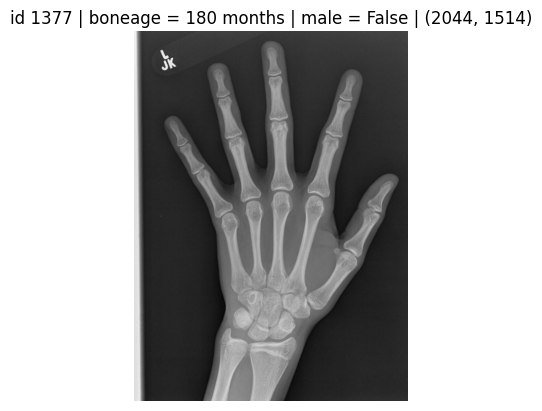

In [5]:
row = df.iloc[0]
img = cv2.imread(str(TRAIN_IMG_DIR / f"{row.id}.png"), cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap="gray")
plt.title(f"id {row.id} | boneage = {row.boneage} months | male = {row.male} | {img.shape}")
plt.axis("off")
plt.show()